### 1. Import Library dan Konfigurasi Visualisasi
Sel ini bertugas mengimpor library yang diperlukan (OpenCV, Pandas, NumPy, Matplotlib, Seaborn) serta mengatur konfigurasi tema grafik.


In [ ]:
import os
import sys
from pathlib import Path
import cv2                
from PIL import Image      
import numpy as np         
import pandas as pd       
import matplotlib.pyplot as plt   
import seaborn as sns             
from tqdm.auto import tqdm


plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110  

### 2. Setup Path Direktori Dataset dan Output
Sel ini bertugas menentukan jalur direktori dataset citra dan membuat folder `output_data` secara otomatis.


In [ ]:
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "kode_program":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

DATASET_DIR = PROJECT_ROOT / "dataset" / "BaliCarving"
IMAGES_DIR = DATASET_DIR / "JPEGImages"                 
OUTPUT_DIR = PROJECT_ROOT / "output_data"               
PREPROCESSED_DIR = OUTPUT_DIR / "citra_preprocessed"   


OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PREPROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print(f"Direktori Root Proyek      : {PROJECT_ROOT}")
print(f"Direktori Dataset Asli     : {DATASET_DIR} (Status: {'Ditemukan' if DATASET_DIR.exists() else 'Tidak Ditemukan'})")
print(f"Direktori Citra Bersih     : {PREPROCESSED_DIR}")
print(f"Direktori Output Data      : {OUTPUT_DIR}")


Direktori Root Proyek      : D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1
Direktori Dataset Asli     : D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\dataset\BaliCarving
Direktori Citra Bersih     : D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\citra_preprocessed
Direktori Output Data      : D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data


### 3. Pemuatan Anotasi, Pemetaan 5 Motif Utama, dan Penyimpanan CSV
Sel ini bertugas membaca anotasi dataset, memetakan ke 5 motif utama (Barong, Goak, Gajah, Daun, Cina), memverifikasi keberadaan file fisik gambar, dan menyimpannya ke `output_data/data_ukiran.csv`.


In [ ]:
# 1. Membaca Dua File Anotasi Bawaan Dataset (Split trainval dan test)
tv_path = DATASET_DIR / "classification_trainval_ukiran.csv"
te_path = DATASET_DIR / "classification_test_ukiran.csv"

df_tv = pd.read_csv(tv_path)
df_te = pd.read_csv(te_path)

# Menggabungkan kedua split menjadi satu dataset utuh berjumlah 2.364 citra
df_all = pd.concat([df_tv, df_te], ignore_index=True)

# Daftar 7 kolom label multi-label asli pada dataset
motif_cols = ['Barong', 'Cina', 'Punggel', 'Keketusan', 'Daun', 'Gajah', 'Goak']

def parse_motif(row):
    active = [c for c in motif_cols if row[c] == 1]
    comb = '+'.join(active)
    
    # Penentuan motif utama pembeda
    if 'Cina' in active:
        utama = 'Cina'
    elif 'Barong' in active:
        utama = 'Barong'
    elif 'Gajah' in active:
        utama = 'Gajah'
    elif 'Goak' in active:
        utama = 'Goak'
    elif 'Daun' in active:
        utama = 'Daun'
    else:
        utama = 'Lainnya'
    return pd.Series([comb, utama], index=['kombinasi_motif', 'motif_utama'])

# Menjalankan pemetaan untuk setiap baris data
parsed = df_all.apply(parse_motif, axis=1)
df_all['kombinasi_motif'] = parsed['kombinasi_motif']
df_all['motif_utama'] = parsed['motif_utama']

# 2. Menyeragamkan Format Nama File dan Jalur Relatifnya
df_all['nama_file'] = df_all['name'].apply(lambda x: f"{x}.jpg")
df_all['path_relatif'] = df_all['nama_file'].apply(lambda f: str(Path("dataset") / "BaliCarving" / "JPEGImages" / f))

# 3. Verifikasi Keberadaan Fisik File Citra di Harddisk
df_all['file_tersedia'] = df_all['nama_file'].apply(lambda f: (IMAGES_DIR / f).exists())

print(f"Total entri citra terdata: {len(df_all)}")
print(f"File terverifikasi fisik : {df_all['file_tersedia'].sum()} / {len(df_all)} (Lengkap)")

# 4. Menyimpan Hasil Metadata ke File data_ukiran.csv
csv_output_path = OUTPUT_DIR / "data_ukiran.csv"
df_all.to_csv(csv_output_path, index=False)
print(f"File label berhasil disimpan ke: {csv_output_path}")

# Menampilkan 5 baris pertama data
df_all[['nama_file', 'motif_utama', 'kombinasi_motif']].head(5)


Total entri citra terdata: 2364
File terverifikasi fisik : 2364 / 2364
File label berhasil disimpan ke: D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\data_ukiran.csv


,nama_file,motif_utama,kombinasi_motif
0,train (1).jpg,Gajah,Punggel+Keketusan+Gajah
1,train (2).jpg,Gajah,Punggel+Keketusan+Gajah
2,train (3).jpg,Gajah,Punggel+Keketusan+Gajah
3,train (4).jpg,Barong,Barong+Punggel+Keketusan
4,train (5).jpg,Barong,Barong+Punggel+Keketusan
5,train (6).jpg,Barong,Barong+Punggel+Keketusan
6,train (7).jpg,Barong,Barong+Punggel+Keketusan
7,train (8).jpg,Barong,Barong+Punggel+Keketusan
8,train (9).jpg,Barong,Barong+Punggel+Keketusan
9,train (10).jpg,Barong,Barong+Punggel+Keketusan


### 4. Visualisasi Distribusi Frekuensi Motif (Bar Chart)
Sel ini bertugas menampilkan grafik batang yang memperlihatkan jumlah sampel citra dan persentase untuk setiap motif ukiran Bali.


C:\Users\dektu\AppData\Local\Temp\ipykernel_1880\3534190963.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=counts.index, y=counts.values, palette=colors, edgecolor='black', linewidth=0.8)


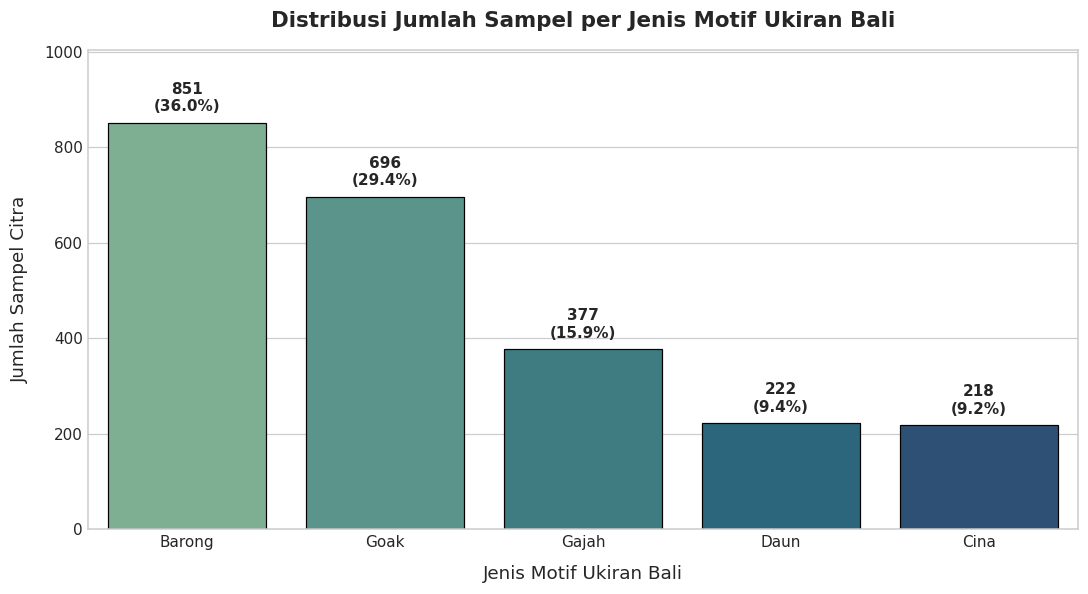

=== RINGKASAN SEBARAN MOTIF UKIRAN BALI ===
- Motif Barong  :  851 citra (36.00%)
- Motif Goak    :  696 citra (29.44%)
- Motif Gajah   :  377 citra (15.95%)
- Motif Daun    :  222 citra (9.39%)
- Motif Cina    :  218 citra (9.22%)


In [12]:
# 1. Menghitung Frekuensi Kemunculan Masing-Masing Motif
counts = df_all['motif_utama'].value_counts()
total_samples = len(df_all)

# 2. Membuat Kanvas Grafik Batang (Bar Chart)
plt.figure(figsize=(10, 5.5))
colors = sns.color_palette("crest", len(counts))

# Menggambar diagram batang menggunakan Seaborn
ax = sns.barplot(x=counts.index, y=counts.values, palette=colors, edgecolor='black', linewidth=0.8)
plt.title("Distribusi Jumlah Sampel per Jenis Motif Ukiran Bali", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Jenis Motif Ukiran Bali", fontsize=12, labelpad=10)
plt.ylabel("Jumlah Sampel Citra", fontsize=12, labelpad=10)

# 3. Menambahkan Teks Angka Riil dan Persentase di Atas Setiap Batang
for i, v in enumerate(counts.values):
    pct = (v / total_samples) * 100
    ax.text(i, v + 18, f"{v:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=10, fontweight="bold")

# Memberikan margin ruang kosong di atas balok tertinggi agar teks tidak terpotong
plt.ylim(0, max(counts.values) * 1.18)
plt.tight_layout()
plt.show()

# 4. Mencetak Ringkasan Statistik ke Konsol
print("=== RINGKASAN SEBARAN MOTIF UKIRAN BALI ===")
for motif, cnt in counts.items():
    print(f"- Motif {motif:<8}: {cnt:>4} citra ({(cnt/total_samples)*100:.2f}%)")


### 5. Definisi Fungsi Prapemrosesan Citra (Resize 224x224 dan CLAHE)
Sel ini bertugas membuat fungsi `preprocess_ukiran` untuk menyeragamkan ukuran citra ke 224x224 piksel dan meningkatkan kontras lekukan pahatan menggunakan CLAHE pada ruang warna LAB.


In [ ]:
def preprocess_ukiran(image_path, target_size=(224, 224), clip_limit=2.5, tile_grid_size=(8, 8)):
    # 1. Membaca citra asli dari file
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
        raise FileNotFoundError(f"Citra tidak ditemukan di: {image_path}")
        
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # 2. Penyeragaman resolusi citra dengan interpolasi INTER_AREA (anti-aliasing terbaik untuk pengecilan)
    img_resized = cv2.resize(img_rgb, target_size, interpolation=cv2.INTER_AREA)
    
    # 3. Konversi ke ruang warna CIE LAB
    lab = cv2.cvtColor(img_resized, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    
    # 4. Peningkatan kontras adaptif lokal dengan CLAHE pada channel intensitas cahaya (Luminance)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    l_clahe = clahe.apply(l_channel)
    
    # 5. Rekonstruksi dan konversi balik ke ruang warna RGB
    lab_clahe = cv2.merge([l_clahe, a_channel, b_channel])
    img_clahe = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2RGB)
    
    return img_resized, img_clahe


### 6. Visualisasi Komparasi Citra Sebelum vs Sesudah Preprocessing
Sel ini bertugas menampilkan sampel citra asli berdampingan dengan hasil Resize + CLAHE untuk masing-masing dari 5 jenis motif ukiran.


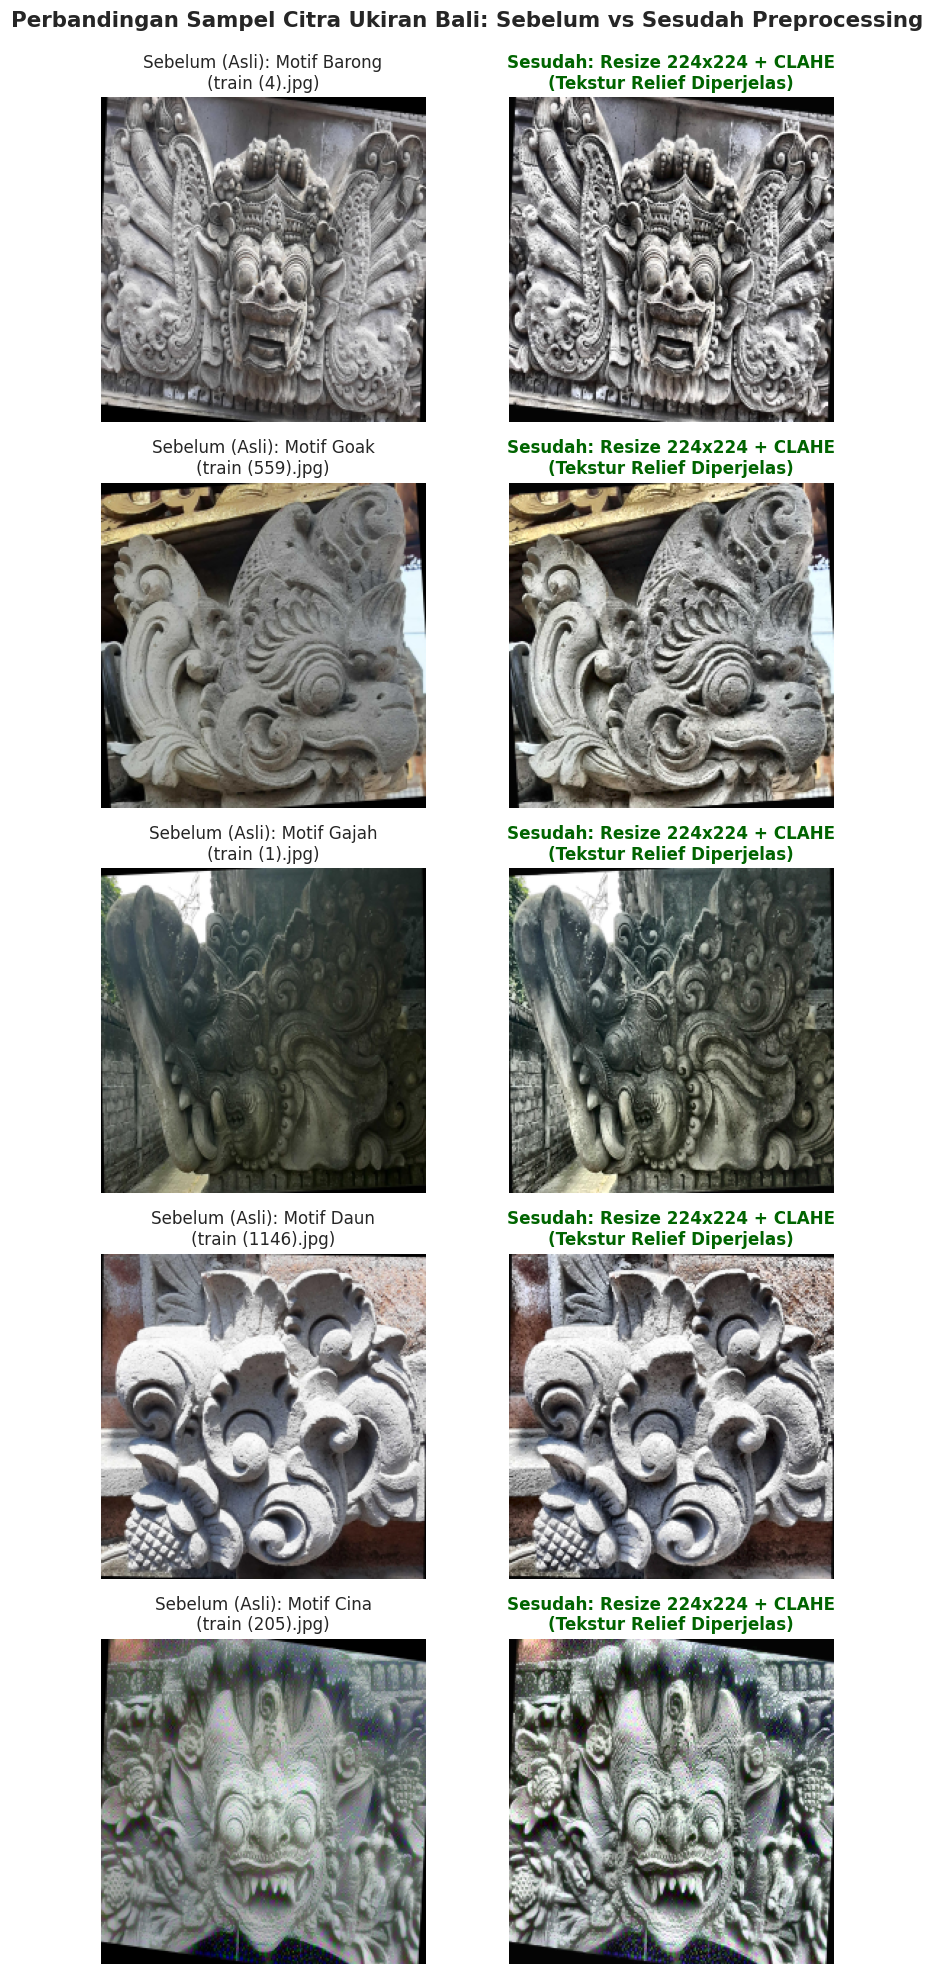

In [14]:
# 1. Mengambil 1 Sampel Citra Representatif dari Masing-Masing Motif
sample_motifs = ['Barong', 'Goak', 'Gajah', 'Daun', 'Cina']
sample_rows = [df_all[df_all['motif_utama'] == m].iloc[0] for m in sample_motifs]

# 2. Menyiapkan Grid Tampilan 5 Baris x 2 Kolom
fig, axes = plt.subplots(len(sample_motifs), 2, figsize=(8, 3.6 * len(sample_motifs)))

# 3. Menampilkan Foto Sebelum vs Sesudah Berdampingan
for idx, row in enumerate(sample_rows):
    img_path = IMAGES_DIR / row['nama_file']
    raw_img, clahe_img = preprocess_ukiran(img_path)
    
    # Kolom Kiri: Citra Asli (Resize 224x224)
    axes[idx, 0].imshow(raw_img)
    axes[idx, 0].set_title(f"Sebelum (Asli): Motif {row['motif_utama']}\n({row['nama_file']})", fontsize=11)
    axes[idx, 0].axis('off') # Menghilangkan garis sumbu koordinat piksel
    
    # Kolom Kanan: Citra Hasil CLAHE (Detail Lekukan Dipertegas)
    axes[idx, 1].imshow(clahe_img)
    axes[idx, 1].set_title(f"Sesudah: Resize 224x224 + CLAHE\n(Tekstur Relief Diperjelas)", fontsize=11, color='darkgreen', fontweight='bold')
    axes[idx, 1].axis('off')

plt.suptitle("Perbandingan Sampel Citra Ukiran Bali: Sebelum vs Sesudah Preprocessing", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()


### 7. Analisis Histogram Intensitas Cahaya (Sebelum vs Sesudah CLAHE)
Sel ini bertugas menampilkan perbandingan grafik histogram intensitas piksel sebelum dan sesudah CLAHE untuk memverifikasi perataan kontras pencahayaan.


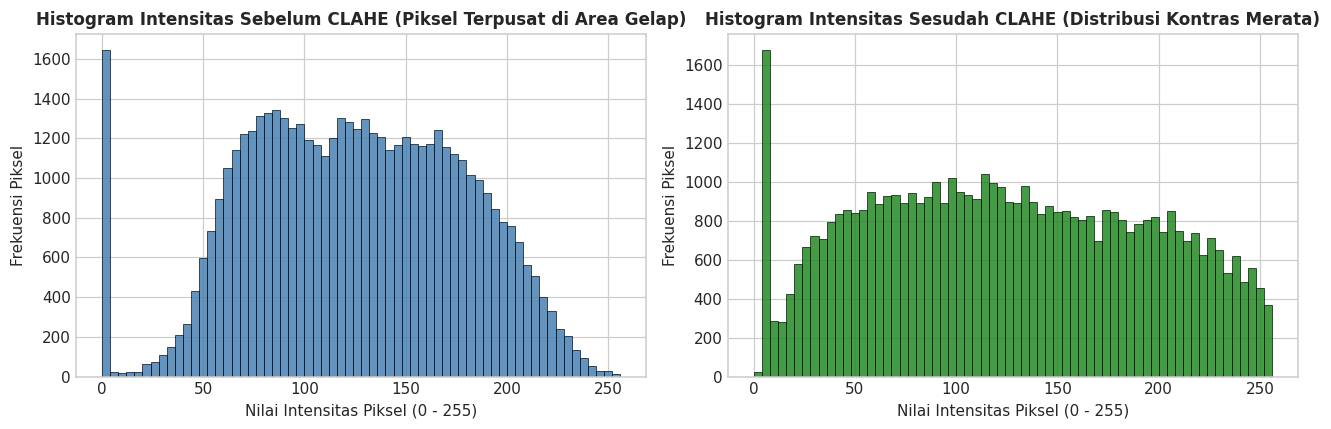

In [15]:
# 1. Mengambil Sampel Citra Barong dan Memprosesnya
sample_barong_path = IMAGES_DIR / sample_rows[0]['nama_file']
raw_img, clahe_img = preprocess_ukiran(sample_barong_path)

# 2. Mengonversi ke Skala Abu-Abu (Grayscale) untuk Mengukur Intensitas Cahaya (0 - 255)
gray_raw = cv2.cvtColor(raw_img, cv2.COLOR_RGB2GRAY)
gray_clahe = cv2.cvtColor(clahe_img, cv2.COLOR_RGB2GRAY)

# 3. Membuat Dua Grafik Histogram Berdampingan
plt.figure(figsize=(12, 4))

# Histogram Sebelum CLAHE
plt.subplot(1, 2, 1)
# gray_raw.ravel() meratakan matriks 2D menjadi 1D agar bisa dihitung sebaran pikselnya
plt.hist(gray_raw.ravel(), bins=64, range=(0, 256), color='steelblue', alpha=0.85, edgecolor='black', linewidth=0.5)
plt.title("Histogram Intensitas Sebelum CLAHE (Piksel Terpusat di Area Gelap)", fontsize=11, fontweight="bold")
plt.xlabel("Nilai Intensitas Piksel (0 - 255)")
plt.ylabel("Frekuensi Piksel")

# Histogram Sesudah CLAHE
plt.subplot(1, 2, 2)
plt.hist(gray_clahe.ravel(), bins=64, range=(0, 256), color='forestgreen', alpha=0.85, edgecolor='black', linewidth=0.5)
plt.title("Histogram Intensitas Sesudah CLAHE (Distribusi Kontras Merata)", fontsize=11, fontweight="bold")
plt.xlabel("Nilai Intensitas Piksel (0 - 255)")
plt.ylabel("Frekuensi Piksel")

plt.tight_layout()
plt.show()


### 8. Memproses Seluruh 2.364 Citra dan Menyimpan ke Folder output_data/citra_preprocessed/
Sel ini bertugas menjalankan fungsi `preprocess_ukiran` (Resize 224x224 + CLAHE) untuk seluruh 2.364 citra dan menyimpannya secara fisik ke folder `output_data/citra_preprocessed/` sebagai artefak hasil nyata prapemrosesan.


In [16]:
# 1. Menyiapkan Konfigurasi CLAHE
clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
print(f"Menyimpan seluruh citra hasil prapemrosesan ke: {PREPROCESSED_DIR}")

# 2. Perulangan untuk Memproses Seluruh 2.364 Citra
for idx, row in tqdm(df_all.iterrows(), total=len(df_all), desc="Menyimpan Citra Preprocessed"):
    src_path = IMAGES_DIR / row['nama_file']
    dst_path = PREPROCESSED_DIR / row['nama_file']
    
    # Lewati jika file sudah ada di folder agar tidak perlu komputasi ulang
    if not dst_path.exists():
        img_bgr = cv2.imread(str(src_path))
        if img_bgr is not None:
            # Resize ke ukuran seragam 224x224 piksel
            img_resized = cv2.resize(img_bgr, (224, 224), interpolation=cv2.INTER_AREA)
            
            # Peningkatan kontras CLAHE pada ruang warna LAB
            lab = cv2.cvtColor(img_resized, cv2.COLOR_BGR2LAB)
            l, a, b = cv2.split(lab)
            l_clahe = clahe.apply(l)
            lab_clahe = cv2.merge([l_clahe, a, b])
            final_bgr = cv2.cvtColor(lab_clahe, cv2.COLOR_LAB2BGR)
            
            # Simpan citra bersih secara fisik ke folder output_data/citra_preprocessed/
            cv2.imwrite(str(dst_path), final_bgr)

# 3. Mencatat Jalur Citra Bersih ke dalam data_ukiran.csv
df_all['path_preprocessed'] = df_all['nama_file'].apply(lambda f: str(Path("output_data") / "citra_preprocessed" / f))
df_all.to_csv(csv_output_path, index=False)

print(f"Selesai! Seluruh {len(df_all)} citra bersih telah tersimpan di: {PREPROCESSED_DIR}")
print(f"File metadata terbarui: {csv_output_path}")


Menyimpan seluruh citra hasil prapemrosesan ke: D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\citra_preprocessed


Menyimpan Citra Preprocessed:   0%|          | 0/2364 [00:00<?, ?it/s]

Selesai! Seluruh 2364 citra bersih telah tersimpan di: D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\citra_preprocessed
File metadata terbarui: D:\Kuliah\SMT 7\Machine Learning\PROJEK AKHIR ML\studiKasus1\output_data\data_ukiran.csv
